# Textbook Bertrand: LLM prices versus the mathematical equilibrium

Two firms sell an identical product and choose prices simultaneously. The cheaper firm supplies all demand; an exact tie splits demand equally. Total demand is linear and nonnegative:

$$Q(P)=\max(a-bP,0),\qquad
q_i(p_i,p_j)=\begin{cases}
Q(p_i),&p_i<p_j,\\
Q(p_i)/2,&p_i=p_j,\\
0,&p_i>p_j.
\end{cases}$$

Costs are $C_i(q_i)=cq_i$ and profits are $\pi_i=(p_i-c)q_i$. For identical constant marginal costs, unlimited capacity and positive demand at cost, the textbook Bertrand–Nash equilibrium is $p_A=p_B=c$. This is an individual-incentive equilibrium, **not** the joint-profit maximum.

The LLMs receive the piecewise rule, demand parameters, costs, and price bounds. They do not receive the solver's answer or the rival's current price. The solver operates separately on the same mechanism.

**Live API mode is enabled below.** Credentials/model are loaded from `.env` (`API_KEY`, `MODEL`). Switch `USE_LIVE_API=False` for a deterministic, deliberately off-equilibrium integration fixture. No action is hardcoded in the live mode. [Textbook reference: Princeton ECO 300, slide 5](https://www.princeton.edu/~dixitak/Teaching/MicroLowCalculus/Slides/Lec16.pdf).


In [1]:
from IPython.display import Markdown, display
import matplotlib.pyplot as plt
import numpy as np

from examples.bertrand import BertrandExampleSettings, run_job, run_live_job
from components.common.economics.models import LinearDemand
from components.mechanisms.bertrand import HomogeneousBertrandMechanism, BertrandParameters
from simulation_core.logging import replay, stream_action_trace
from simulation_core.types import Action

SETTINGS = BertrandExampleSettings(a=100.0, b=1.0, marginal_cost=20.0,
                                   price_lower=0.0, price_upper=100.0)
USE_LIVE_API = True
with stream_action_trace():
    artifact = run_live_job(SETTINGS) if USE_LIVE_API else run_job(SETTINGS)
config, result, benchmark = artifact.manifest.simulation, artifact.result, artifact.benchmark
assert benchmark is not None
mode = "LIVE MODEL" if USE_LIVE_API else "FAKE GATEWAY — fixed test prices"
display(Markdown(f"**Mode:** {mode} · **Status:** {result.status} · **Rounds:** {result.final_state.tick}"))
params = BertrandParameters.model_validate(config.world.parameters)
actor_ids = tuple(actor.id for actor in config.world.actors)
print(f"Demand: Q(P) = max({params.demand.a:g} - {params.demand.b:g}*P, 0)")
print("Marginal costs:", params.marginal_costs)
print("Feasible continuous prices:", params.price_domain.model_dump())
print("Benchmark status:", benchmark.result.status)
print("Benchmark method:", benchmark.result.diagnostics.get("method"))
print("Only exact equality counts as a price tie; there is no cents grid or tie tolerance.")


{"tick": 1, "actor_id": "A", "action": {"actor_id": "A", "kind": "set_price", "payload": {"price": 20.0}}, "rationale": "Costs are 20 for both, lowest price takes all demand. My goal is maximize own profit. I assume rival will price near cost to win sales. Pricing above 20 risks zero sales, pricing below 20 gives losses since cost is 20. Pricing at 20 guarantees non-negative profit and is the Nash equilibrium."}


{"tick": 1, "actor_id": "B", "action": {"actor_id": "B", "kind": "set_price", "payload": {"price": 20.0}}, "rationale": "Both firms have cost 20 and the lower price gets all demand Q=100-P. I set price equal to cost to maximize profit because pricing higher risks getting zero sales if rival undercuts, and pricing lower would lose money. I assume rival will also price near cost."}


**Mode:** LIVE MODEL · **Status:** completed · **Rounds:** 1

Demand: Q(P) = max(100 - 1*P, 0)
Marginal costs: {'A': 20.0, 'B': 20.0}
Feasible continuous prices: {'lower': 0.0, 'upper': 100.0}
Benchmark status: solved
Benchmark method: Analytical equal-cost homogeneous Bertrand equilibrium plus region-wise best-response checks
Only exact equality counts as a price tie; there is no cents grid or tie tolerance.


## What the firms observe

This is the exact configured public economic information supplied to both firms. Observations also include each firm's own private memory. Prices remain hidden until the entire batch commits.


In [2]:
display(config.world.initial_public_state["market"])
first_calls = [call for call in result.events[1].model_calls if call.status == "accepted"]
assert len(first_calls) == len(actor_ids)
assert all(call.mode == ("live" if USE_LIVE_API else "fake") for call in first_calls)


{'demand': {'a': 100.0, 'b': 1.0, 'formula': 'Q(P) = max(a - b*P, 0)'},
 'firm_demand_piecewise': 'For two firms i and j: q_i = Q(p_i) if p_i < p_j; q_i = Q(p_i)/2 if p_i = p_j; q_i = 0 if p_i > p_j.',
 'costs': {'A': 20.0, 'B': 20.0},
 'cost_formula': 'C_i(q_i) = c_i*q_i; no fixed costs',
 'profit_formula': 'profit_i = (p_i - c_i)*q_i',
 'price_domain': {'lower': 0.0, 'upper': 100.0},
 'price_convention': 'Continuous prices, no price grid or rounding; ties require exact equality.',
 'capacity': 'Unlimited; firms supply allocated demand.',
 'timing': "One-shot simultaneous choices; rival's uncommitted price is not visible."}

## Actual LLM choices and mathematical benchmark

The reference is the **Bertrand–Nash equilibrium**, not a joint optimum. Deltas below are actor-run outcomes minus the benchmark. Negative or positive profit differences alone do not establish optimal behavior: unilateral deviation gains measure whether a firm could earn more while its rival's price stayed fixed.


In [3]:
assert benchmark.result.status == "solved", benchmark.result.diagnostics
assert len(benchmark.result.equilibria) == 1
equilibrium = benchmark.result.equilibria[0]
comparison = benchmark.comparisons[0]
observed = result.outcomes[-1]
prices = {action.actor_id: action.payload["price"] for action in result.events[-1].actions}
reference_prices = {action.actor_id: action.payload["price"] for action in equilibrium.actions}
quantities = observed.metrics["quantities"]
reference_quantities = equilibrium.outcome.metrics["quantities"]
rows = ["| Firm | LLM price | Nash price | Price delta | LLM quantity | Nash quantity | LLM profit | Nash profit | Deviation-gain supremum |",
        "|---|---:|---:|---:|---:|---:|---:|---:|---:|"]
for aid in actor_ids:
    rows.append(f"| {aid} | {prices[aid]:.6g} | {reference_prices[aid]:.6g} | "
                f"{comparison.numeric_action_deltas[aid]['price']:+.6g} | {quantities[aid]:.6g} | "
                f"{reference_quantities[aid]:.6g} | {observed.payoffs[aid]:.6g} | "
                f"{equilibrium.outcome.payoffs[aid]:.6g} | {benchmark.observed_regrets[aid]:.6g} |")
display(Markdown("\n".join(rows)))
print("LLM outcome total quantity:", observed.metrics["total_quantity"])
print("Nash total quantity:", equilibrium.outcome.metrics["total_quantity"])
print("Unilateral gains at the benchmark:", equilibrium.regrets)
print("Benchmark qualifications:", benchmark.result.diagnostics["scope"])
if not USE_LIVE_API:
    assert prices == {"A": 30.0, "B": 25.0}
    assert observed.payoffs == {"A": 0.0, "B": 375.0}


| Firm | LLM price | Nash price | Price delta | LLM quantity | Nash quantity | LLM profit | Nash profit | Deviation-gain supremum |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| A | 20 | 20 | +0 | 40 | 40 | 0 | 0 | 0 |
| B | 20 | 20 | +0 | 40 | 40 | 0 | 0 | 0 |

LLM outcome total quantity: 80.0
Nash total quantity: 80.0
Unilateral gains at the benchmark: {'A': 0.0, 'B': 0.0}
Benchmark qualifications: Nash equilibrium, not joint-profit maximization; no price grid or tie tolerance


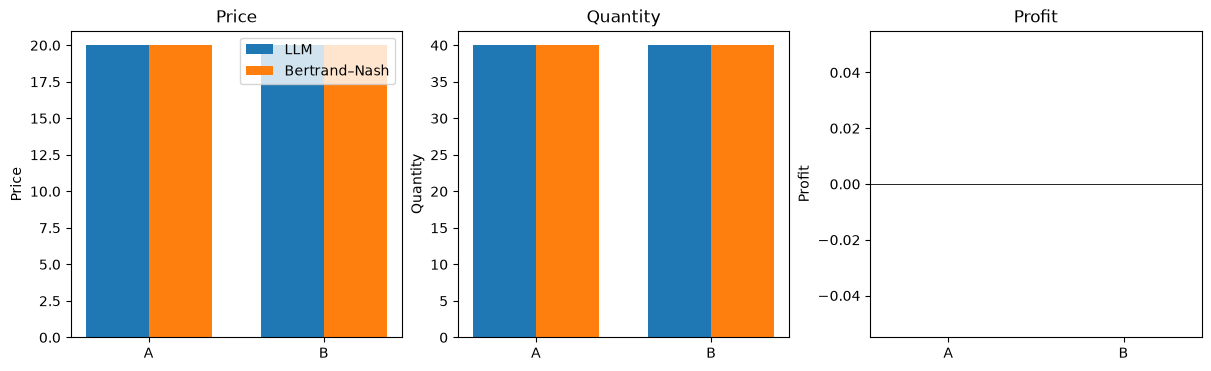

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), constrained_layout=True)
x = np.arange(len(actor_ids))
panels = [("Price", prices, reference_prices),
          ("Quantity", quantities, reference_quantities),
          ("Profit", observed.payoffs, equilibrium.outcome.payoffs)]
for ax, (label, actual, reference) in zip(axes, panels):
    ax.bar(x-.18, [actual[aid] for aid in actor_ids], width=.36,
           label="LLM" if USE_LIVE_API else "Fake-gateway fixture")
    ax.bar(x+.18, [reference[aid] for aid in actor_ids], width=.36, label="Bertrand–Nash")
    ax.set(xticks=x, xticklabels=actor_ids, ylabel=label, title=label)
    ax.axhline(0, color="black", linewidth=.6)
axes[0].legend()
plt.show()


## Piecewise firm demand

The aggregate curve is linear until demand reaches zero. Firm demand jumps at the rival's price: just below it the firm serves the entire market, at an exact tie it serves half, and above it it serves none. The dots show each firm's realized price/quantity. Plotted samples illustrate the mechanism; they are not a numerical price-grid solver.


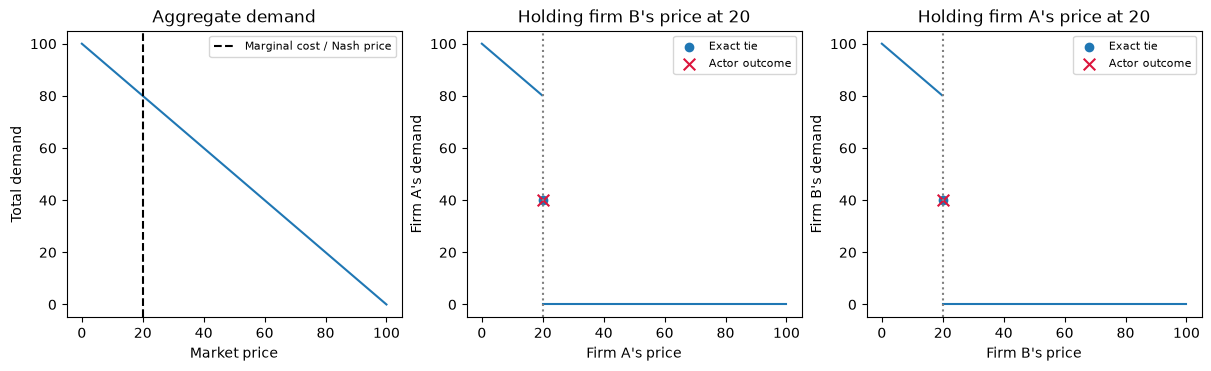

In [5]:
mechanism = HomogeneousBertrandMechanism()
precommit = result.events[-2].state
price_grid = np.linspace(params.price_domain.lower, params.price_domain.upper, 300)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), constrained_layout=True)
axes[0].plot(price_grid, [params.demand.quantity(float(p)) for p in price_grid])
axes[0].axvline(SETTINGS.marginal_cost, color="black", linestyle="--", label="Marginal cost / Nash price")
axes[0].set(xlabel="Market price", ylabel="Total demand", title="Aggregate demand")
axes[0].legend(fontsize=8)
for ax, aid in zip(axes[1:], actor_ids):
    rival = next(other for other in actor_ids if other != aid)
    rival_price = prices[rival]
    below = [float(p) for p in price_grid if p < rival_price]
    above = [float(p) for p in price_grid if p > rival_price]
    def firm_quantity(own_price):
        profile = tuple(Action(actor_id=other, kind=params.action_kind,
                    payload={"price": float(own_price if other == aid else prices[other])})
                    for other in actor_ids)
        return mechanism.evaluate(config.world, precommit, profile).metrics["quantities"][aid]
    ax.plot(below, [firm_quantity(p) for p in below], color="tab:blue")
    ax.plot(above, [firm_quantity(p) for p in above], color="tab:blue")
    ax.scatter([rival_price], [params.demand.quantity(rival_price)/2], color="tab:blue", label="Exact tie")
    ax.scatter([prices[aid]], [quantities[aid]], marker="x", color="crimson", s=70, label="Actor outcome")
    ax.axvline(rival_price, color="gray", linestyle=":")
    ax.set(xlabel=f"Firm {aid}'s price", ylabel=f"Firm {aid}'s demand",
           title=f"Holding firm {rival}'s price at {rival_price:g}")
    ax.legend(fontsize=8)
plt.show()


## Why each firm chose its price

These are the model's concise stated rationales, recorded with each committed decision. They are not private internal reasoning. The explanations are produced before either firm observes its rival's current price.


In [6]:
for event in result.events:
    for decision in event.decisions:
        print(f"Turn {event.state.tick} | Firm {decision.action.actor_id} | Price {decision.action.payload['price']:g}")
        print(f"Stated rationale: {decision.rationale}\n")
        assert decision.rationale


Turn 1 | Firm A | Price 20
Stated rationale: Costs are 20 for both, lowest price takes all demand. My goal is maximize own profit. I assume rival will price near cost to win sales. Pricing above 20 risks zero sales, pricing below 20 gives losses since cost is 20. Pricing at 20 guarantees non-negative profit and is the Nash equilibrium.

Turn 1 | Firm B | Price 20
Stated rationale: Both firms have cost 20 and the lower price gets all demand Q=100-P. I set price equal to cost to maximize profit because pricing higher risks getting zero sales if rival undercuts, and pricing lower would lose money. I assume rival will also price near cost.



## Continuous best-response qualifications

Against some above-cost rival prices, the highest possible payoff is a **supremum** approached by pricing arbitrarily close below the rival. The exact tied price splits demand and does not attain that payoff. Such cases have no claimed maximizing action; a feasible nearby witness is shown separately. An attained best response (for example, a monopoly price below a sufficiently expensive rival) is identified explicitly.


In [7]:
for aid, response in benchmark.observed_best_responses.items():
    print(f"Firm {aid}: current profit={response.current_payoff:g}, "
          f"best-response supremum={response.supremum_payoff:g}, gain={response.gain:g}")
    print("  Supremum attained:", response.attained)
    print("  Maximizing action:", None if response.maximizing_action is None else response.maximizing_action.payload)
    print("  Feasible witness:", response.witness_action.payload, "with profit", response.witness_payoff)
print("No finite price grid or fictitious minimum undercut was used to find the equilibrium.")


Firm A: current profit=0, best-response supremum=0, gain=0
  Supremum attained: True
  Maximizing action: {'price': 20.0}
  Feasible witness: {'price': 20.0} with profit 0.0
Firm B: current profit=0, best-response supremum=0, gain=0
  Supremum attained: True
  Maximizing action: {'price': 20.0}
  Feasible witness: {'price': 20.0} with profit 0.0
No finite price grid or fictitious minimum undercut was used to find the equilibrium.


## Provenance and canonical replay

Full internal events contain prompts, responses, rationales, and private memory. The summary exposes call metadata only. Replay reconstructs states without calling the model or rerunning economic calculations.


In [8]:
rows = ["| Firm | Mode | Model | Attempt | Status | Input tokens | Output tokens |",
        "|---|---|---|---:|---|---:|---:|"]
for call in result.model_calls:
    rows.append(f"| {call.actor_id} | {call.mode} | {call.response_model or call.model} | {call.attempt} | "
                f"{call.status} | {call.input_tokens} | {call.output_tokens} |")
display(Markdown("\n".join(rows)))
assert replay(result.events)[-1] == result.final_state
assert type(artifact).model_validate_json(artifact.model_dump_json()) == artifact
print("Replay matches final state. Job artifact JSON round-trip passed.")
print("Benchmark configuration SHA-256:", benchmark.config_sha256)


| Firm | Mode | Model | Attempt | Status | Input tokens | Output tokens |
|---|---|---|---:|---|---:|---:|
| A | live | muse-spark-1.3-contributor | 1 | accepted | 776 | 941 |
| B | live | muse-spark-1.3-contributor | 1 | accepted | 776 | 563 |

Replay matches final state. Job artifact JSON round-trip passed.
Benchmark configuration SHA-256: fee0afbdef1023f5a5a0057d0bdec2e0ba52d5a43ed881cdf9365aa4e8012e61


## Configured assumptions

The default numbers are illustrative inputs, not estimated market data. The baseline is a one-round, complete-information spot market with identical constant costs, no capacity constraints or fixed costs, continuous bounded prices, exact ties, and nonnegative demand. A multi-round run would compare stage outcomes against the one-shot benchmark and would not establish a repeated-game equilibrium.


In [9]:
for assumption in result.assumptions:
    print(f"[{assumption.source}] {assumption.path}: {assumption.rationale}")


[default] /world/parameters: Illustrative linear demand and identical constant marginal costs; numbers are explicit synthetic configuration, not calibrated data. Prices are continuous and bounded.
[textbook] /world/initial_public_state/market: Homogeneous products, unlimited capacity, no fixed costs, complete information; lowest price takes all demand and an exact tie splits it equally. Demand is truncated at zero.
[default] /permissions: Each firm knows demand, both marginal costs and price bounds; only committed past prices and outcomes are public. Private memory remains actor-specific.
[default] /protocol_parameters/rounds: One simultaneous round by default. More rounds are independent spot-market comparisons to a stage-game benchmark, not a repeated-game equilibrium claim.
